# How much better is the best model?, per task phase → `figure_model_comparison_stimulus.pdf`, `figure_model_comparison_delay.pdf`

[`../figure_4/figure_model_comparison.ipynb`](../figure_4/figure_model_comparison.ipynb)'s
panel, drawn once on the stimulus-period firing rate and once on the delay-period rate, so a
reader can see whether the ranking of the models belongs to one phase of the trial.

Each phase is a **refit**, not a subset: every model is fit to the firing rate over the **stimulus** period (0–1000 ms after stimulus onset, objects on screen) or the **delay** period (1000–2000 ms, objects gone) instead of the 2-s stimulus + delay window the main figure uses. The population is not re-selected: the shared 2-object modulation criterion is computed once on the 2-s window and applied first, so both phases are drawn over the same neurons as the main figure. The caches are built by `build_cache.py`; see `common.py` for how the window is switched. The Poisson likelihood is evaluated on the spike count in that 1-s window, so the
per-trial differences are on a different scale from the main figure's 2-s ones — compare the
*ordering* of the models across panels, not their distances.

**What the point and its whisker are.** The point is the *population* estimate — the total
held-out log-likelihood difference over all neurons and trials, divided by the total trial
count — and the whisker is a **95% confidence interval of the mean across neurons**, with each
neuron treated as one independent observation regardless of session. What it does not cover is
session-to-session variation: simultaneously recorded neurons share trials, share a stimulus
sequence and have correlated receptive fields, so the session is the unit that is plausibly
independent, and the cluster-robust error across sessions is wider by `inflation`. Both are
computed here and printed beside each other, so the size of that gap is visible rather than
asserted. The axis is a likelihood rather than a log-likelihood: the reference sits at 1, and
0.91 means each held-out trial is 9% less likely under that model.

Nothing is refit here: every number comes from the per-phase fit cache's `dtest_ll_mean` (the
paired per-split held-out ΔLL against a constant fit to the same trials) times each neuron's
trial count. The reference model and every difference are judged within the phase drawn.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

import common
common.set_style()
import elpd_lib as el
import models_lib as ml

# ── These must match ../figure_4/figure_model_comparison.ipynb ────────────────
# The supplement is that panel per task phase; if a knob here differs, the two are
# different analyses and the split no longer shows what it claims to.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)
LABELS = ml.MODEL_LABELS_SHORT

N_BOOT = 2000          # session-level bootstrap draws

# ── Style, matched to ../figure_4/figure_model_comparison.ipynb ───────────────
# The accents of figure_ks_stats.ipynb, so the panels read together.
ACCENT, ACCENT_MODEL = '#c1272d', 'future_field'
SECOND_ACCENT, SECOND_ACCENT_MODEL = '#8e3b6b', 'basis_function'
GRAY_LIGHT, GRAY_DARK = 0.82, 0.2


def model_colors(models=MODELS):
    accents = {ACCENT_MODEL: ACCENT, SECOND_ACCENT_MODEL: SECOND_ACCENT}
    n_grey = sum(m not in accents for m in models)
    greys = iter(np.linspace(GRAY_LIGHT, GRAY_DARK, max(n_grey, 1)))
    return {m: (accents[m] if m in accents else str(next(greys))) for m in models}


COLORS = model_colors()
SUBJECTS = ('Perle', 'Elgar')
TITLES = {'Perle': 'Monkey P', 'Elgar': 'Monkey E'}

FIGSIZE = (5.5, 3.1)
OUTPUT = 'figure_model_comparison_{group}.pdf'
XTICK_ROTATION = -50   # degrees; 0 is horizontal
XTICK_HA = 'left'      # 'left' evenly spaces the labels' LEFT ends under their ticks ...
XTICK_SHIFT_IN = -0.2  # ... and puts the block right of them, which this shifts back

# WSPACE is constrained layout's MINIMUM gap and it bottoms out well short of zero — the right
# panel has its own y tick labels, since the animals do not share a scale. COLUMN_SHIFT_IN
# slides that panel left, in INCHES, after the layout has settled, which is the only way past
# the floor.
WSPACE = 0.08
COLUMN_SHIFT_IN = 0.35

POINT_SIZE = 10          # diameter of the summary marker, in points
ERR_LINEWIDTH = 1.2      # its error bar
ERR_CAPSIZE = 4

YLABEL = 'Relative likelihood'


## The comparison

One table per animal per group: the total held-out log-likelihood difference against the
reference, divided by the total trial count, with the 95% confidence interval across neurons
(what the figure draws) beside the cluster-robust standard error across sessions and the
session-level bootstrap. `inflation` is the ratio of the session-level and neuron-level standard
errors — how much a flat, neuron-level interval understates the session-to-session uncertainty.

In [2]:
fits = common.selected_fits_by_phase(MODELS)

tables = {}
for group, summary in fits:
    print(f'══ {group} ' + '═' * 56)
    tables[group] = {}
    for s_ in SUBJECTS:
        t = el.elpd_table(summary, MODELS, subject=s_, n_boot=N_BOOT)
        tables[group][TITLES[s_]] = t
        print(f'── {TITLES[s_]} — reference: {t.attrs["reference"]} '
              f'({t["n_neurons"].iat[0]} neurons, {t["n_clusters"].iat[0]} sessions)')
        display(t[['model', 'delta_per_unit', 'neuron_ci_lo_per_unit',
                   'neuron_ci_hi_per_unit', 'se_cluster_per_unit', 'lo_per_unit',
                   'hi_per_unit', 'se_neuron_per_unit', 'inflation']].round(5))


2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
stimulus: 1339 neurons enter the figure
2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
delay: 1339 neurons enter the figure
══ stimulus ════════════════════════════════════════════════════════
── Monkey P — reference: future_field (998 neurons, 10 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.05060,-0.05842,-0.04278,0.01562,-0.08065,-0.02484,0.00399,3.91812
1,normalization,-0.03968,-0.04673,-0.03263,0.01318,-0.06672,-0.01742,0.00359,3.66876
2,inhibition,-0.01220,-0.02181,-0.00259,0.00712,-0.02716,-0.00066,0.00490,1.45377
3,basis_function,-0.00128,-0.00245,-0.00011,0.00076,-0.00284,0.00003,0.00060,1.27035
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


── Monkey E — reference: future_field (341 neurons, 12 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.03398,-0.04369,-0.02427,0.01043,-0.05504,-0.01604,0.00494,2.11246
1,normalization,-0.02538,-0.03282,-0.01794,0.00833,-0.04176,-0.01133,0.00378,2.20158
2,inhibition,-0.01864,-0.02731,-0.00998,0.00847,-0.03594,-0.00484,0.00440,1.92356
3,basis_function,-0.00125,-0.00341,0.00092,0.00122,-0.00371,0.00102,0.00110,1.10635
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


══ delay ════════════════════════════════════════════════════════
── Monkey P — reference: future_field (998 neurons, 10 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.07186,-0.08328,-0.06044,0.02426,-0.12063,-0.03620,0.00582,4.16857
1,normalization,-0.05832,-0.06848,-0.04815,0.02127,-0.10107,-0.02720,0.00518,4.10682
2,inhibition,-0.04680,-0.05630,-0.03731,0.01201,-0.07163,-0.02634,0.00484,2.48158
3,basis_function,0.00014,-0.00146,0.00175,0.00107,-0.00206,0.00178,0.00082,1.30971
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


── Monkey E — reference: future_field (341 neurons, 12 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.01483,-0.01873,-0.01094,0.00284,-0.02019,-0.00990,0.00198,1.43577
1,normalization,-0.01056,-0.01394,-0.00717,0.00270,-0.01588,-0.00578,0.00172,1.56536
2,inhibition,-0.00266,-0.00750,0.00218,0.00196,-0.00639,0.00087,0.00246,0.79696
3,basis_function,0.00093,-0.00027,0.00214,0.00068,-0.00022,0.00235,0.00061,1.11530
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


## The figures

Drawn exactly as the main panel is — same model order, same colours, same rotated labels — so
the supplement and the figure can be read against each other without discounting a difference
in how they are drawn. The dashed line at 1 is the reference model, and each point's distance
from it is that model's shortfall.

The panels do **not** share a y axis: the two animals differ several-fold in the size of the
differences, and a shared scale makes the smaller one unreadable to make a point the numbers
already make.

saved figure_model_comparison_stimulus.pdf


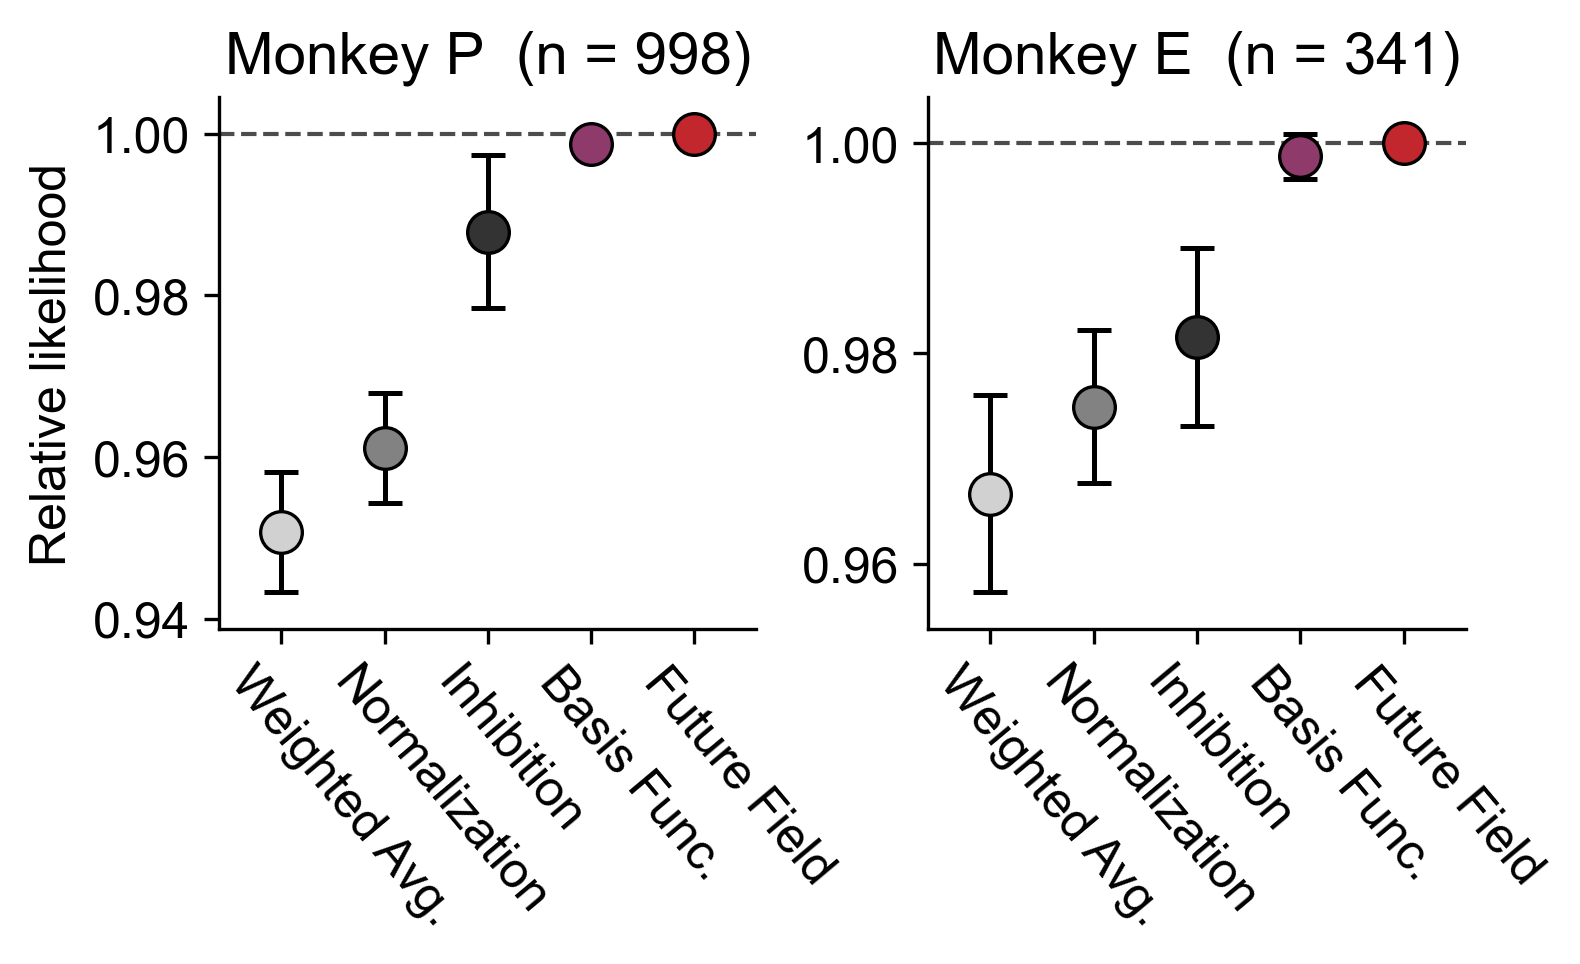

saved figure_model_comparison_delay.pdf


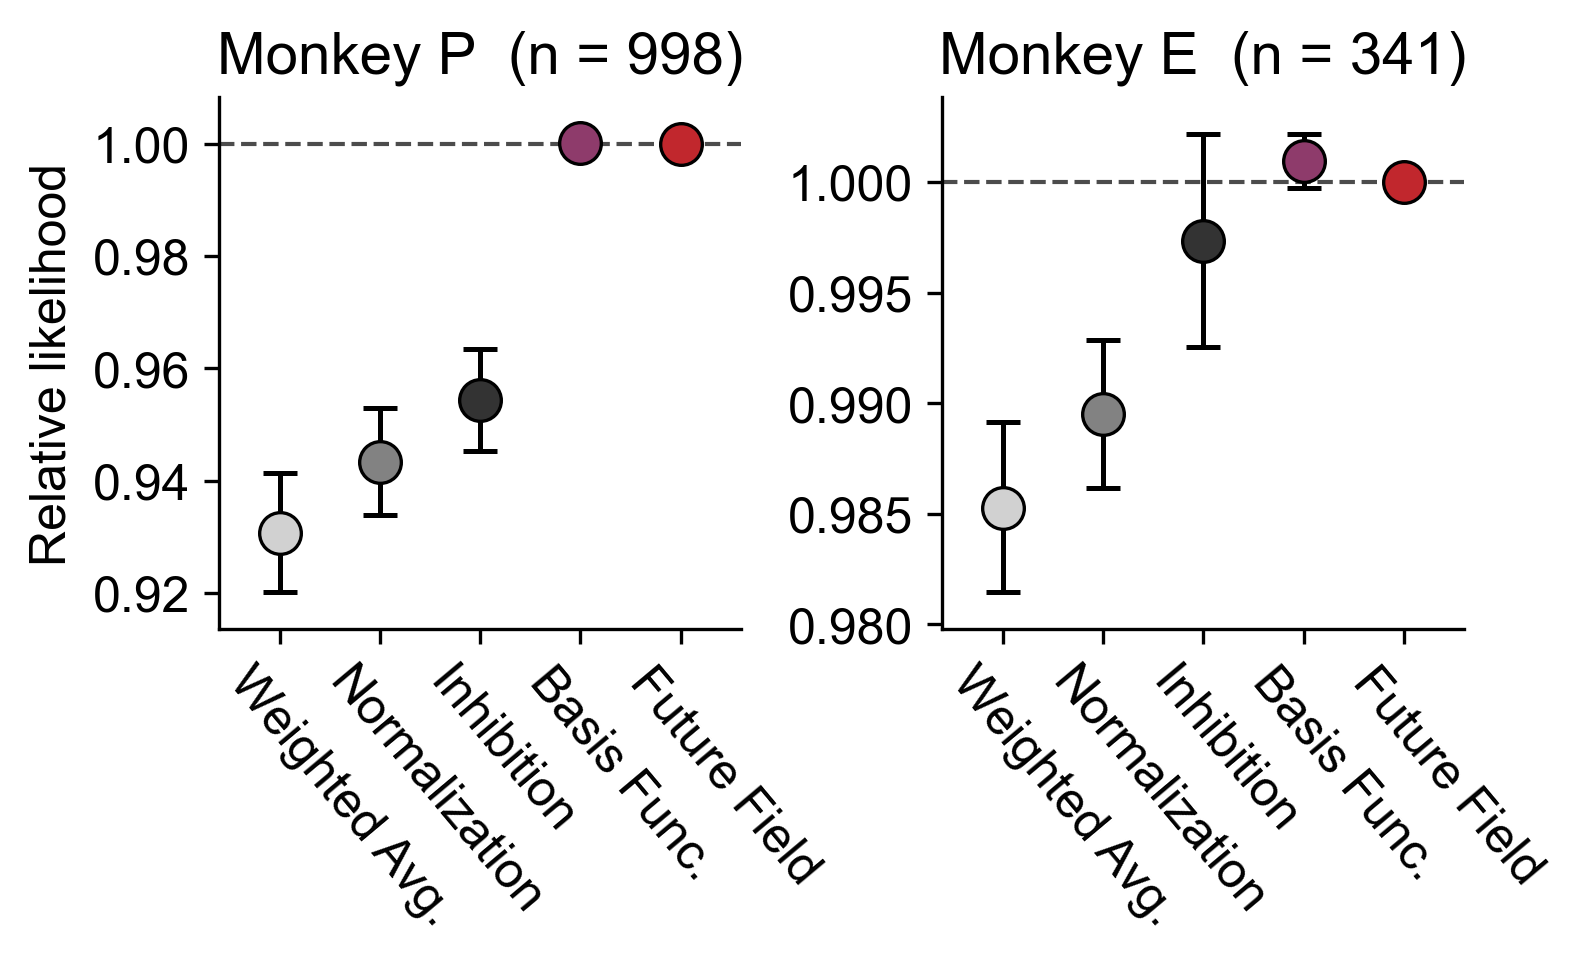

In [3]:
summaries = dict(fits)
for group, per_subject in tables.items():
    pop = summaries[group].drop_duplicates(['subject', 'session', 'unit'])
    n_by_subject = {TITLES[s_]: int((pop['subject'] == s_).sum()) for s_ in SUBJECTS}
    fig = el.plot_elpd(per_subject, COLORS, figsize=FIGSIZE, labels=LABELS,
                       xtick_rotation=XTICK_ROTATION, xtick_ha=XTICK_HA,
                       shift_in=XTICK_SHIFT_IN, n_by_subject=n_by_subject,
                       wspace=WSPACE, column_shift_in=COLUMN_SHIFT_IN, ylabel=YLABEL,
                       point_size=POINT_SIZE, err_linewidth=ERR_LINEWIDTH,
                       err_capsize=ERR_CAPSIZE)
    common.save(fig, OUTPUT.format(group=group))
    plt.show()


## The constant-rate model

Every likelihood here is already measured against a neuron that **ignores the stimulus**, so
that model is the origin of the whole scale. It is printed rather than drawn, as in the main
figure: on this axis it sits far below every model shown, and a line there would flatten them
all against the top.

What it gives is the size of the thing being argued over. The models differ from each other by a
few per cent per trial; they differ from a constant rate by very much more, and the *worst* of
them already recovers most of that distance — which is the reading that has to survive the
split by phase for the supplement to be reassuring.

In [4]:
for group, summary in fits:
    for s_ in SUBJECTS:
        t = tables[group][TITLES[s_]]
        _, units, c0 = el.per_neuron_delta(summary, MODELS, t.attrs['reference'], subject=s_)
        worst = t['delta_per_unit'].min()
        print(f'{group}  {TITLES[s_]}  (reference {t.attrs["reference"]})')
        print(f'    constant rate: {c0:+.4f} nats/trial  ->  relative likelihood '
              f'{np.exp(c0):.4f} per trial, {np.exp(c0 * units["n_2obj"].mean()):.3g} per neuron')
        print(f'    worst model:   {worst:+.4f} nats/trial  ->  {np.exp(worst):.4f} per trial, '
              f'i.e. {100 * (1 - worst / c0):.0f}% of the way from a constant rate to the best')


stimulus  Monkey P  (reference future_field)
    constant rate: -0.2472 nats/trial  ->  relative likelihood 0.7810 per trial, 3.35e-85 per neuron
    worst model:   -0.0506 nats/trial  ->  0.9507 per trial, i.e. 80% of the way from a constant rate to the best
stimulus  Monkey E  (reference future_field)
    constant rate: -0.1185 nats/trial  ->  relative likelihood 0.8883 per trial, 1.03e-42 per neuron
    worst model:   -0.0340 nats/trial  ->  0.9666 per trial, i.e. 71% of the way from a constant rate to the best


delay  Monkey P  (reference future_field)
    constant rate: -0.2164 nats/trial  ->  relative likelihood 0.8054 per trial, 1.16e-74 per neuron
    worst model:   -0.0719 nats/trial  ->  0.9307 per trial, i.e. 67% of the way from a constant rate to the best
delay  Monkey E  (reference future_field)
    constant rate: -0.0762 nats/trial  ->  relative likelihood 0.9267 per trial, 1.02e-27 per neuron
    worst model:   -0.0148 nats/trial  ->  0.9853 per trial, i.e. 81% of the way from a constant rate to the best
